# Part 1: Probability Distributions with the EM Algorithm
We treat the heights of children and fathers (Galton data) as an unlabeled mixture of two Gaussian distributions and fit it from scratch with Expectation-Maximization.

In [9]:
from data_prep import build_mixture, load_galton
from em_algorithm import fit_em, predict_posterior
from mean_split import count_uncertain, mean_split_summary
from plots import plot_fit, plot_log_likelihood
from reporting import build_tracking_table

## 1. Data
The CSV has one row per child, so each father's height is repeated for every child in his family. We keep one row per family (205 fathers) and combine them with all 934 children into one unlabeled list of 1139 heights. The labels are kept aside only for checking, and EM never sees them.

In [10]:
df = load_galton()
heights, labels = build_mixture(df)
print(len(heights), "heights:", int((labels == 0).sum()), "children and", int((labels == 1).sum()), "fathers")

1139 heights: 934 children and 205 fathers


## 2. The EM algorithm
- **Initialization:** two means placed one standard deviation either side of the overall mean, equal variances, equal weights (0.5 each).
- **E-step:** for every height, compute the probability (responsibility) that it belongs to each group, using the current means, variances and weights.
- **M-step:** update each group's mean, variance and weight, using the responsibilities as weights.
- **Stop** when the log-likelihood changes by less than 1e-6 (or after 200 iterations).

In [11]:
params, history = fit_em(heights)

## 3. Optimization tracking table
Parameters and log-likelihood at initialization and the first two iterations. The log-likelihood rises at every step. Component 1 is the lower-height group and component 2 the upper-height group.

In [12]:
build_tracking_table(history)

,Iteration,mu1,mu2,var1,var2,pi1,pi2,Log-Likelihood
0,0 (Initialization),63.6414,70.7756,12.7241,12.7241,0.5000,0.5000,-3194.5755
1,1,64.9339,69.4553,7.9124,7.3183,0.4969,0.5031,-3053.3088
2,2,64.8745,69.5053,7.7363,6.9965,0.4960,0.5040,-3052.1871


## 4. Fitted model and convergence
The red line is the global mean. It cuts through the region where the two fitted curves overlap. The second plot shows most of the improvement happening in the first few iterations, after which the log-likelihood flattens.

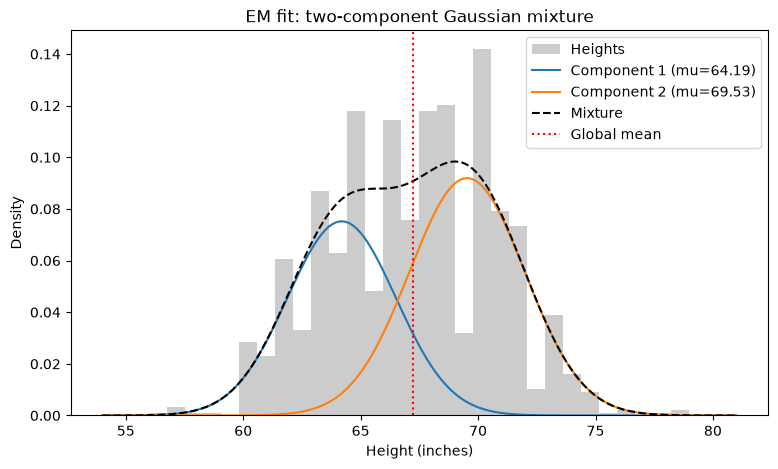

In [13]:
fig = plot_fit(heights, params)

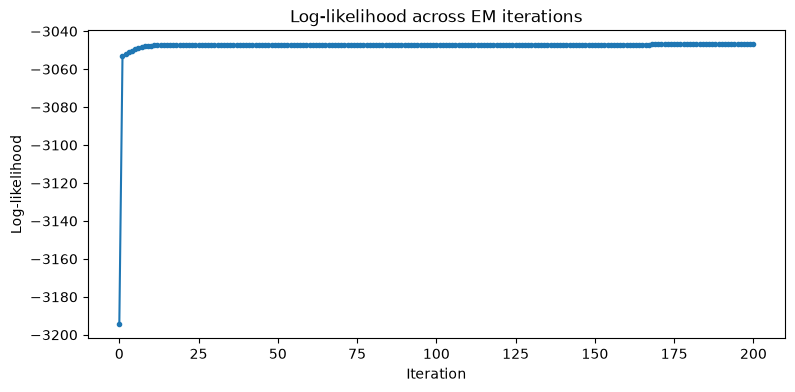

In [14]:
fig = plot_log_likelihood(history)

## 5. Classifying a test height
The posterior probabilities come from the E-step formula, applied to a single height with the final fitted parameters.

In [15]:
test_height = 67
posterior = predict_posterior(test_height, params)
print(f"Height {test_height}: P(group 1, lower) = {posterior[0]:.4f}, P(group 2, upper) = {posterior[1]:.4f}")

Height 67: P(group 1, lower) = 0.3995, P(group 2, upper) = 0.6005


## 6. Why not split at the global mean?
A hard cut at the mean forces every person into exactly one group, ignores the groups' different sizes and spreads, and mislabels many people near the line. EM gives a probability instead, so it can say when a height is genuinely uncertain.

In [16]:
summary = mean_split_summary(heights, labels)
print("Global mean threshold:", round(summary["threshold"], 2))
print("Children in upper pile:", summary["children_in_upper_pile"], "of", int((labels == 0).sum()))
print("Fathers in lower pile:", summary["fathers_in_lower_pile"], "of", int((labels == 1).sum()))
print("Accuracy vs labels:", round(summary["accuracy"], 3))
print("Heights EM is unsure about:", count_uncertain(heights, params))

Global mean threshold: 67.21
Children in upper pile: 403 of 934
Fathers in lower pile: 44 of 205
Accuracy vs labels: 0.608
Heights EM is unsure about: 309
